# Étudiant 1 — Dataset & Baseline (Nada)
**Projet : étude de l'optimisation de l'entraînement d'un petit Transformer**

Contenu du notebook :
1. Choix et téléchargement du dataset (SST-2, classification de sentiment)
2. Nettoyage avec Pandas
3. Split Train / Validation / Test
4. Tokenisation
5. Fine-tuning de DistilBERT (fonction `run_experiment` réutilisable par toute l'équipe)
6. Baseline + comparaison des Learning Rates (4 expériences)

> Runtime Colab : *Exécution > Modifier le type d'exécution > GPU (T4)*.

In [1]:
!pip -q install datasets transformers scikit-learn

## 0. Configuration commune
`BASE_CONFIG` est la **configuration de référence** que les étudiants 2, 3 et 4 reprendront. On ne change qu'un paramètre à la fois.

In [2]:
import os, time, json, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from datasets import load_dataset, Dataset, DatasetDict
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_scheduler)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

SEED = 42
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU (active le GPU !)")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

MODEL_NAME = "distilbert-base-uncased"

BASE_CONFIG = dict(
    name="baseline",
    model_name=MODEL_NAME,
    lr=2e-5,
    warmup_ratio=0.0,        # étudiant 2
    scheduler="linear",      # étudiant 2 : linear / cosine / constant
    batch_size=32,           # étudiant 3
    optimizer="adamw",       # étudiant 3 : adamw / sgd
    weight_decay=0.01,
    epochs=3,
    max_len=64,
    eval_every=50,           # évaluation sur validation tous les 50 steps (courbes de convergence)
    eval_test=False,         # le Test n'est évalué QUE pour la configuration finale (voir section 9)
    seed=SEED,               # même seed pour tous les runs
)

# Dossier de sauvegarde (Drive recommandé pour ne rien perdre)
USE_DRIVE = True    # /content/results est temporaire : Drive conserve les résultats après la session
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = "/content/drive/MyDrive/projet_transformer/results"
else:
    RESULTS_DIR = "/content/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

Device : cuda | Tesla T4
Mounted at /content/drive


## 1. Choix et téléchargement du dataset
**SST-2** (Stanford Sentiment Treebank, version GLUE) : classification binaire de sentiment (positif / négatif).
Pourquoi ce choix : textes courts (entraînement rapide, < 10 min), labels propres, référence classique, DistilBERT atteint ~90 % d'accuracy.

In [4]:
raw = load_dataset("nyu-mll/glue", "sst2")
print(raw)
train_raw = raw["train"].to_pandas()
test_raw = raw["validation"].to_pandas()   # le vrai "test" de GLUE n'a pas de labels -> on utilise cette partie comme Test
train_raw.head()

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

... (2 outputs left out)

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})


,sentence,label,idx
0,hide new secretions from the parental units,0,0
1,"contains no wit , only labored gags",0,1
2,that loves its characters and communicates som...,1,2
3,remains utterly satisfied to remain the same t...,0,3
4,on the worst revenge-of-the-nerds clichés the ...,0,4


## 2. Nettoyage avec Pandas

In [5]:
def clean(df):
    df = df.copy()
    n0 = len(df)
    df = df.drop(columns=[c for c in ["idx"] if c in df.columns])
    df = df.dropna(subset=["sentence", "label"])
    df["sentence"] = df["sentence"].str.strip().str.replace(r"\s+", " ", regex=True)
    df = df[df["sentence"].str.split().str.len() >= 3]      # on retire les fragments trop courts
    df = df.drop_duplicates(subset="sentence")
    df["label"] = df["label"].astype(int)
    print(f"{n0} -> {len(df)} lignes après nettoyage")
    return df.reset_index(drop=True)

train_clean = clean(train_raw)
test_clean = clean(test_raw)

print("\nDistribution des classes (train) :")
print(train_clean["label"].value_counts(normalize=True).round(3))
print("\nLongueur moyenne (mots) :", train_clean["sentence"].str.split().str.len().mean().round(1))

67349 -> 55803 lignes après nettoyage
872 -> 870 lignes après nettoyage

Distribution des classes (train) :
label
1    0.554
0    0.446
Name: proportion, dtype: float64

Longueur moyenne (mots) : 11.0


## 3. Split Train / Validation / Test
Pour respecter le budget (< 10 min par run), on travaille sur un sous-échantillon stratifié :
**6000 train / 1000 validation** (tirés du train GLUE) et **Test = split de validation officiel de GLUE nettoyé** (~800 exemples), jamais utilisé pour choisir les hyperparamètres.

In [6]:
sub = train_clean.sample(n=7000, random_state=SEED)
train_df, val_df = train_test_split(sub, test_size=1000, stratify=sub["label"], random_state=SEED)
test_df = test_clean

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):5d} exemples | % positifs = {d['label'].mean():.3f}")

# Sauvegarde du dataset préparé pour l'équipe
os.makedirs(f"{RESULTS_DIR}/data", exist_ok=True)
train_df.to_csv(f"{RESULTS_DIR}/data/train.csv", index=False)
val_df.to_csv(f"{RESULTS_DIR}/data/val.csv", index=False)
test_df.to_csv(f"{RESULTS_DIR}/data/test.csv", index=False)

train:  6000 exemples | % positifs = 0.549
val  :  1000 exemples | % positifs = 0.549
test :   870 exemples | % positifs = 0.509


## 4. Tokenisation (Hugging Face Tokenizers)
Padding dynamique : chaque batch est complété à la longueur de sa phrase la plus longue (plus rapide).

In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_hf(df):
    return Dataset.from_pandas(df.reset_index(drop=True), preserve_index=False)

ds = DatasetDict(train=to_hf(train_df), validation=to_hf(val_df), test=to_hf(test_df))

def tokenize(batch):
    return tokenizer(batch["sentence"], truncation=True, max_length=BASE_CONFIG["max_len"])

ds = ds.map(tokenize, batched=True)
ds = ds.remove_columns(["sentence"]).rename_column("label", "labels")
ds.set_format("torch")
collator = DataCollatorWithPadding(tokenizer)
print(ds)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/6000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/870 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 6000
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 870
    })
})


## 5. Fonction d'entraînement réutilisable
`run_experiment(config)` fine-tune DistilBERT et enregistre : hyperparamètres, temps, Train Loss (par step), Validation Loss / Accuracy / F1 (tous les `eval_every` steps), mémoire GPU max, métriques Test finales.
Les étudiants 2, 3 et 4 n'ont qu'à copier cette fonction et changer `scheduler`, `warmup_ratio`, `batch_size`, `optimizer`.

In [8]:
def compute_metrics(labels, preds):
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    return dict(accuracy=accuracy_score(labels, preds), precision=p, recall=r, f1=f1)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, n, all_preds, all_labels = 0.0, 0, [], []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            out = model(**batch)
        bs = batch["labels"].size(0)
        total_loss += out.loss.item() * bs
        n += bs
        all_preds += out.logits.argmax(-1).cpu().tolist()
        all_labels += batch["labels"].cpu().tolist()
    model.train()
    return dict(loss=total_loss / n, **compute_metrics(all_labels, all_preds))

def build_optimizer(model, cfg):
    if cfg["optimizer"] == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    if cfg["optimizer"] == "sgd":
        return torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9, weight_decay=cfg["weight_decay"])
    raise ValueError(cfg["optimizer"])

def run_experiment(cfg):
    cfg = {**BASE_CONFIG, **cfg}
    print(f"\n=== {cfg['name']} === lr={cfg['lr']} | warmup={cfg['warmup_ratio']} | sched={cfg['scheduler']} "
          f"| bs={cfg['batch_size']} | opt={cfg['optimizer']}")
    set_seed(cfg["seed"])

    # Chronométrage complet : préparation des DataLoaders + chargement du modèle + entraînement
    # + éventuelle évaluation Test. La synchronisation CUDA rend la mesure GPU plus fiable.
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()

    train_loader = DataLoader(ds["train"], batch_size=cfg["batch_size"], shuffle=True, collate_fn=collator)
    val_loader = DataLoader(ds["validation"], batch_size=128, collate_fn=collator)
    test_loader = DataLoader(ds["test"], batch_size=128, collate_fn=collator)

    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    model = AutoModelForSequenceClassification.from_pretrained(cfg["model_name"], num_labels=2).to(device)
    optimizer = build_optimizer(model, cfg)
    total_steps = cfg["epochs"] * len(train_loader)
    scheduler = get_scheduler(cfg["scheduler"], optimizer=optimizer,
                              num_warmup_steps=int(cfg["warmup_ratio"] * total_steps),
                              num_training_steps=total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

    train_losses, evals = [], []
    step = 0
    model.train()

    for epoch in range(cfg["epochs"]):
        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                loss = model(**batch).loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            step += 1
            train_losses.append(loss.item())

            if step % cfg["eval_every"] == 0 or step == total_steps:
                m = evaluate(model, val_loader)
                evals.append(dict(step=step, epoch=epoch + 1, train_loss=float(np.mean(train_losses[-cfg["eval_every"]:])),
                                  lr_now=scheduler.get_last_lr()[0], **{f"val_{k}": v for k, v in m.items()}))
                print(f"step {step:4d}/{total_steps} | train_loss {evals[-1]['train_loss']:.4f} | "
                      f"val_loss {m['loss']:.4f} | val_acc {m['accuracy']:.4f} | val_f1 {m['f1']:.4f}")

    peak_mem = torch.cuda.max_memory_allocated() / 1024**2 if device == "cuda" else 0.0
    test = evaluate(model, test_loader) if cfg["eval_test"] else None

    # Sauvegarder uniquement le modèle final retenu (pas les modèles intermédiaires).
    if cfg["eval_test"]:
        final_model_dir = f"{RESULTS_DIR}/final_model"
        model.save_pretrained(final_model_dir)
        tokenizer.save_pretrained(final_model_dir)
        print(f"   Modèle final et tokenizer sauvegardés dans : {final_model_dir}")

    if device == "cuda":
        torch.cuda.synchronize()
    total_run_time = time.time() - t0

    last = evals[-1]
    result = dict(
        config=cfg, train_time_s=round(total_run_time, 1), peak_gpu_mem_mb=round(peak_mem, 0),
        final_train_loss=last["train_loss"], final_val_loss=last["val_loss"],
        final_val_acc=last["val_accuracy"], final_val_f1=last["val_f1"],
        best_val_acc=max(e["val_accuracy"] for e in evals),
        test_acc=test["accuracy"] if test else None, test_precision=test["precision"] if test else None,
        test_recall=test["recall"] if test else None, test_f1=test["f1"] if test else None,
        train_losses=train_losses, evals=evals,
    )
    with open(f"{RESULTS_DIR}/{cfg['name']}.json", "w") as f:
        json.dump(result, f)
    print(f"-> durée totale (chargement + préparation + entraînement" +
          (" + Test" if test else "") + f") : {total_run_time:.0f}s | val_acc {last['val_accuracy']:.4f} | mémoire GPU {peak_mem:.0f} Mo")
    if test:
        print(f"   TEST : acc {test['accuracy']:.4f} | f1 {test['f1']:.4f}")
    if total_run_time > 600:
        print("   ATTENTION : durée totale > 600s (10 min). Réduis epochs ou la taille du train set, puis relance TOUS les runs avec les mêmes réglages.")
    else:
        print("   OK : durée totale dans la limite de 600s.")
    del model, optimizer
    if device == "cuda":
        torch.cuda.empty_cache()
    return result

## 6. Baseline (Expérience 1/4)
Configuration de référence : AdamW, LR = 2e-5, batch 32, sans warmup, scheduler linéaire, 3 epochs.

In [9]:
results = {}
results["baseline"] = run_experiment(dict(name="baseline"))
print(f"\nTemps de la baseline : {results['baseline']['train_time_s']:.0f}s (budget : 600s par run)")


=== baseline === lr=2e-05 | warmup=0.0 | sched=linear | bs=32 | opt=adamw


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


step   50/564 | train_loss 0.6006 | val_loss 0.3949 | val_acc 0.8440 | val_f1 0.8434
step  100/564 | train_loss 0.3585 | val_loss 0.3243 | val_acc 0.8720 | val_f1 0.8717
step  150/564 | train_loss 0.3243 | val_loss 0.2946 | val_acc 0.8830 | val_f1 0.8821
step  200/564 | train_loss 0.2890 | val_loss 0.3025 | val_acc 0.8810 | val_f1 0.8792
step  250/564 | train_loss 0.2159 | val_loss 0.2788 | val_acc 0.8870 | val_f1 0.8862
step  300/564 | train_loss 0.2103 | val_loss 0.2775 | val_acc 0.8940 | val_f1 0.8934
step  350/564 | train_loss 0.1959 | val_loss 0.2711 | val_acc 0.8970 | val_f1 0.8960
step  400/564 | train_loss 0.1734 | val_loss 0.2712 | val_acc 0.8990 | val_f1 0.8978
step  450/564 | train_loss 0.1473 | val_loss 0.2811 | val_acc 0.9030 | val_f1 0.9023
step  500/564 | train_loss 0.1312 | val_loss 0.2877 | val_acc 0.8990 | val_f1 0.8981
step  550/564 | train_loss 0.1266 | val_loss 0.2881 | val_acc 0.8990 | val_f1 0.8984
step  564/564 | train_loss 0.1308 | val_loss 0.2878 | val_acc 0.8

**Vérification du budget temps** : regarde le temps de la baseline avant de continuer.
Si elle dépasse 10 min, réduis `epochs` (ex. 2) ou le nombre d'exemples du split (section 3), puis relance la baseline : tous les runs doivent garder les mêmes réglages.

## 7. Comparaison des Learning Rates (Expériences 2 à 4)
On ne change **que** le LR ; tout le reste est identique à la baseline.

In [10]:
for lr in [1e-5, 5e-5, 1e-4]:
    name = f"lr_{lr:.0e}"
    results[name] = run_experiment(dict(name=name, lr=lr))


=== lr_1e-05 === lr=1e-05 | warmup=0.0 | sched=linear | bs=32 | opt=adamw


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


step   50/564 | train_loss 0.6677 | val_loss 0.6036 | val_acc 0.8050 | val_f1 0.8031
step  100/564 | train_loss 0.4708 | val_loss 0.3673 | val_acc 0.8570 | val_f1 0.8556
step  150/564 | train_loss 0.3578 | val_loss 0.3318 | val_acc 0.8650 | val_f1 0.8638
step  200/564 | train_loss 0.3370 | val_loss 0.3244 | val_acc 0.8710 | val_f1 0.8694
step  250/564 | train_loss 0.2851 | val_loss 0.3120 | val_acc 0.8770 | val_f1 0.8763
step  300/564 | train_loss 0.2677 | val_loss 0.3059 | val_acc 0.8760 | val_f1 0.8754
step  350/564 | train_loss 0.2532 | val_loss 0.2977 | val_acc 0.8830 | val_f1 0.8824
step  400/564 | train_loss 0.2464 | val_loss 0.2894 | val_acc 0.8810 | val_f1 0.8800
step  450/564 | train_loss 0.2319 | val_loss 0.2924 | val_acc 0.8840 | val_f1 0.8833
step  500/564 | train_loss 0.2086 | val_loss 0.2943 | val_acc 0.8880 | val_f1 0.8872
step  550/564 | train_loss 0.2097 | val_loss 0.2947 | val_acc 0.8860 | val_f1 0.8853
step  564/564 | train_loss 0.2125 | val_loss 0.2945 | val_acc 0.8

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


step   50/564 | train_loss 0.5094 | val_loss 0.3768 | val_acc 0.8440 | val_f1 0.8440
step  100/564 | train_loss 0.3333 | val_loss 0.3295 | val_acc 0.8650 | val_f1 0.8650
step  150/564 | train_loss 0.3082 | val_loss 0.2699 | val_acc 0.8890 | val_f1 0.8884
step  200/564 | train_loss 0.2472 | val_loss 0.2992 | val_acc 0.8970 | val_f1 0.8958
step  250/564 | train_loss 0.1575 | val_loss 0.3026 | val_acc 0.9000 | val_f1 0.8997
step  300/564 | train_loss 0.1454 | val_loss 0.2654 | val_acc 0.9030 | val_f1 0.9024
step  350/564 | train_loss 0.1446 | val_loss 0.2705 | val_acc 0.9120 | val_f1 0.9112
step  400/564 | train_loss 0.1076 | val_loss 0.2906 | val_acc 0.9120 | val_f1 0.9109
step  450/564 | train_loss 0.0718 | val_loss 0.2976 | val_acc 0.9180 | val_f1 0.9170
step  500/564 | train_loss 0.0593 | val_loss 0.2981 | val_acc 0.9160 | val_f1 0.9151
step  550/564 | train_loss 0.0544 | val_loss 0.3049 | val_acc 0.9170 | val_f1 0.9164
step  564/564 | train_loss 0.0619 | val_loss 0.3043 | val_acc 0.9

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


step   50/564 | train_loss 0.5228 | val_loss 0.3675 | val_acc 0.8400 | val_f1 0.8400
step  100/564 | train_loss 0.3359 | val_loss 0.3006 | val_acc 0.8810 | val_f1 0.8802
step  150/564 | train_loss 0.3134 | val_loss 0.2603 | val_acc 0.8910 | val_f1 0.8902
step  200/564 | train_loss 0.2637 | val_loss 0.2949 | val_acc 0.9000 | val_f1 0.8986
step  250/564 | train_loss 0.1322 | val_loss 0.3529 | val_acc 0.8870 | val_f1 0.8853
step  300/564 | train_loss 0.1394 | val_loss 0.2780 | val_acc 0.9070 | val_f1 0.9064
step  350/564 | train_loss 0.1367 | val_loss 0.3080 | val_acc 0.9040 | val_f1 0.9023
step  400/564 | train_loss 0.1014 | val_loss 0.3183 | val_acc 0.9110 | val_f1 0.9094
step  450/564 | train_loss 0.0494 | val_loss 0.3470 | val_acc 0.9150 | val_f1 0.9144
step  500/564 | train_loss 0.0612 | val_loss 0.3223 | val_acc 0.9170 | val_f1 0.9162
step  550/564 | train_loss 0.0489 | val_loss 0.3210 | val_acc 0.9180 | val_f1 0.9174
step  564/564 | train_loss 0.0490 | val_loss 0.3219 | val_acc 0.9

## 8. Résultats : tableau et courbes

In [11]:
rows = []
for name, r in results.items():
    rows.append(dict(config=name, lr=r["config"]["lr"], temps_s=r["train_time_s"], mem_Mo=r["peak_gpu_mem_mb"],
                     train_loss=round(r["final_train_loss"], 4), val_loss=round(r["final_val_loss"], 4),
                     val_acc=round(r["final_val_acc"], 4), val_f1=round(r["final_val_f1"], 4),
                     ))
summary = pd.DataFrame(rows).sort_values("lr")
summary.to_csv(f"{RESULTS_DIR}/summary_student1.csv", index=False)
summary

,config,lr,temps_s,mem_Mo,train_loss,val_loss,val_acc,val_f1
1,lr_1e-05,0.00001,45.7,1316.0,0.2125,0.2945,0.885,0.8842
0,baseline,0.00002,48.5,1319.0,0.1308,0.2878,0.897,0.8963
2,lr_5e-05,0.00005,45.2,1316.0,0.0619,0.3043,0.915,0.9143
3,lr_1e-04,0.00010,45.6,1315.0,0.0490,0.3219,0.916,0.9153


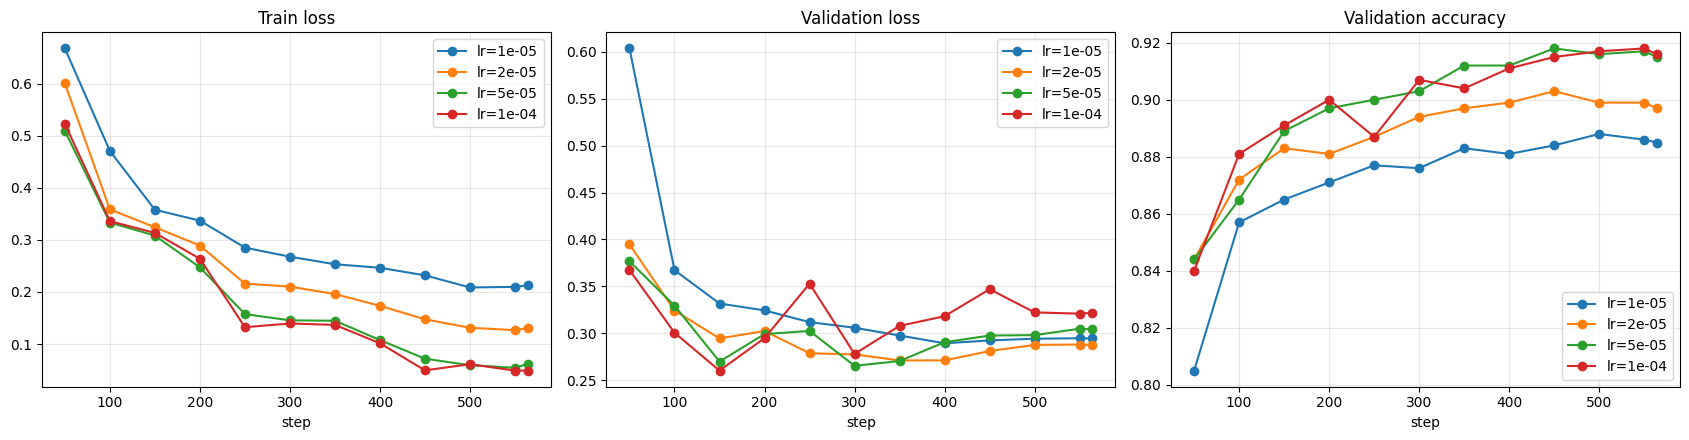

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for name, r in sorted(results.items(), key=lambda kv: kv[1]["config"]["lr"]):
    ev = pd.DataFrame(r["evals"])
    label = f"lr={r['config']['lr']:.0e}"
    axes[0].plot(ev["step"], ev["train_loss"], marker="o", label=label)
    axes[1].plot(ev["step"], ev["val_loss"], marker="o", label=label)
    axes[2].plot(ev["step"], ev["val_accuracy"], marker="o", label=label)
for ax, t in zip(axes, ["Train loss", "Validation loss", "Validation accuracy"]):
    ax.set_title(t); ax.set_xlabel("step"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/lr_comparison.png", dpi=150)
plt.show()

## 9. Choix de la configuration de référence + évaluation Test (une seule fois)
Le LR est choisi **uniquement sur la Validation** (section 8). Le Test n'est évalué qu'ici, pour la configuration retenue.

1. Mets le LR retenu dans `BEST_LR`.
2. Relance ce run avec `eval_test=True` : même seed, mêmes réglages, donc mêmes résultats de validation et en plus les métriques Test.

In [13]:
# Sélection automatique du meilleur LR à partir des résultats de validation des 4 runs.
# Critère principal : meilleur F1 macro sur Validation ; en cas d'égalité, meilleure Accuracy.
comparison_runs = {name: r for name, r in results.items() if name == "baseline" or name.startswith("lr_")}
if len(comparison_runs) != 4:
    raise RuntimeError(f"4 runs de comparaison sont attendus (Baseline + 3 LR), mais {len(comparison_runs)} ont été trouvés. Exécute d'abord les cellules 15 et 18.")

best_name, best_result = max(
    comparison_runs.items(),
    key=lambda item: (item[1]["final_val_f1"], item[1]["final_val_acc"])
)
BEST_LR = best_result["config"]["lr"]
print(f"Meilleur LR sélectionné : {BEST_LR:.0e} ({best_name})")
print(f"Validation F1 : {best_result['final_val_f1']:.4f} | Validation Accuracy : {best_result['final_val_acc']:.4f}")

# Évaluation finale sur le Test avec le LR sélectionné.
final = run_experiment(dict(name="final_reference", lr=BEST_LR, eval_test=True))
print({k: round(final[k], 4) for k in ["test_acc", "test_precision", "test_recall", "test_f1"]})
BASE_CONFIG["lr"] = BEST_LR   # nouvelle configuration de référence pour l'équipe

Meilleur LR sélectionné : 1e-04 (lr_1e-04)
Validation F1 : 0.9153 | Validation Accuracy : 0.9160

=== final_reference === lr=0.0001 | warmup=0.0 | sched=linear | bs=32 | opt=adamw


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


step   50/564 | train_loss 0.5228 | val_loss 0.3675 | val_acc 0.8400 | val_f1 0.8400
step  100/564 | train_loss 0.3359 | val_loss 0.3006 | val_acc 0.8810 | val_f1 0.8802
step  150/564 | train_loss 0.3134 | val_loss 0.2603 | val_acc 0.8910 | val_f1 0.8902
step  200/564 | train_loss 0.2637 | val_loss 0.2949 | val_acc 0.9000 | val_f1 0.8986
step  250/564 | train_loss 0.1322 | val_loss 0.3529 | val_acc 0.8870 | val_f1 0.8853
step  300/564 | train_loss 0.1394 | val_loss 0.2780 | val_acc 0.9070 | val_f1 0.9064
step  350/564 | train_loss 0.1367 | val_loss 0.3080 | val_acc 0.9040 | val_f1 0.9023
step  400/564 | train_loss 0.1014 | val_loss 0.3183 | val_acc 0.9110 | val_f1 0.9094
step  450/564 | train_loss 0.0494 | val_loss 0.3470 | val_acc 0.9150 | val_f1 0.9144
step  500/564 | train_loss 0.0612 | val_loss 0.3223 | val_acc 0.9170 | val_f1 0.9162
step  550/564 | train_loss 0.0489 | val_loss 0.3210 | val_acc 0.9180 | val_f1 0.9174
step  564/564 | train_loss 0.0490 | val_loss 0.3219 | val_acc 0.9

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   Modèle final et tokenizer sauvegardés dans : /content/drive/MyDrive/projet_transformer/results/final_model
-> durée totale (chargement + préparation + entraînement + Test) : 59s | val_acc 0.9160 | mémoire GPU 1315 Mo
   TEST : acc 0.8828 | f1 0.8827
   OK : durée totale dans la limite de 600s.
{'test_acc': 0.8828, 'test_precision': 0.8827, 'test_recall': 0.8828, 'test_f1': 0.8827}


Notes pour le rapport :
- LR trop faible → convergence lente ; LR trop élevé → instabilité de la loss ou dégradation.
- Fichiers à envoyer à l'équipe : ce notebook, `data/*.csv`, `summary_student1.csv`, `lr_comparison.png`, les `*.json`, et la valeur de `BEST_LR`.